# 16. Different training set sizes

In [6]:
ev_all = pd.read_json("../outputs/eval_results.jsonl", lines=True)
ev_all[["model", "split"]].drop_duplicates()

,model,split
0,distilgpt2,test
1,outputs/full/model,test
2,outputs/lora/model,test
4,distilgpt2,general
6,outputs/full/model,general
8,outputs/lora/model,general
9,outputs/f25/model,test
10,outputs/f25/model,general
11,outputs/f50/model,test
12,outputs/f50/model,general


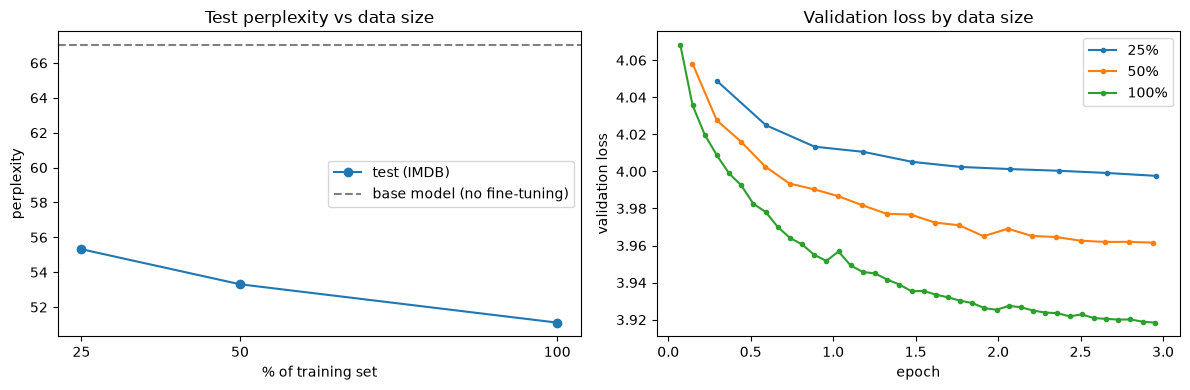

In [7]:
import json, math, pandas as pd, matplotlib.pyplot as plt

runs = {"f25": 25, "f50": 50, "f100": 100}

# Test / general perplexity
ev = pd.read_json("../outputs/eval_results.jsonl", lines=True)
ev["run"] = ev["model"].str.extract(r"outputs/([^/]+)/model")[0].fillna(ev["model"])
ev = ev.drop_duplicates(["run", "split"], keep="last")
ev = ev[ev["run"].isin(runs)]
tab = ev.pivot_table(index="run", columns="split", values="perplexity").round(2)

# Training size, best validation loss, overfitting step from each run's log
for r in runs:
    log = json.load(open(f"../outputs/{r}/log_history.json"))
    env = json.load(open(f"../outputs/{r}/env.json"))
    va = [(x["step"], x["eval_loss"]) for x in log if "eval_loss" in x]
    best_step, best = min(va, key=lambda x: x[1])
    tab.loc[r, "train_%"] = runs[r]
    tab.loc[r, "train_blocks"] = env["train_blocks"]
    tab.loc[r, "total_steps"] = va[-1][0]
    tab.loc[r, "best_val_ppl"] = round(math.exp(best), 2)
    tab.loc[r, "best_step"] = best_step
tab = tab.sort_values("train_%")
tab

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: test perplexity vs data size
axes[0].plot(tab["train_%"], tab["test"], "o-", label="test (IMDB)")
axes[0].axhline(67.01700497167427, ls="--", c="gray", label="base model (no fine-tuning)")   # use your server's base value
axes[0].set_xlabel("% of training set"); axes[0].set_ylabel("perplexity")
axes[0].set_xticks([25, 50, 100]); axes[0].legend(); axes[0].set_title("Test perplexity vs data size")

# Right: validation curves, x = epoch so runs of different length line up
for r in runs:
    log = json.load(open(f"../outputs/{r}/log_history.json"))
    va = [(x["epoch"], x["eval_loss"]) for x in log if "eval_loss" in x]
    axes[1].plot(*zip(*va), "o-", ms=3, label=f"{runs[r]}%")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation loss")
axes[1].legend(); axes[1].set_title("Validation loss by data size")
plt.tight_layout(); plt.show()